## Module 3: Computational Drug Discovery Project Template

Complete the sections below as a team. Remove the word “Template” only if it appears in the final notebook title.    

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).   

## Disease Background: 
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 
Prevalence & incidence, Symptoms, Diagnosis, Standard of care treatments (& reimbursement), Disease progression & prognosis, Biological mechanisms (anatomy, organ physiology, cell & molecular physiology), Clinical Trials/next-gen therapies.

Please provide citations and/or hyperlinks to where you obtained information (including AI) for each of the bullet points.

Obesity is a widespread disease affecting 40.3% of U.S. adults and approximately 940 million adults worldwide. Symptoms include excess body fat, fatigue, reduced mobility, joint pain, and sleep apnea. A BMI of 30 or higher is classified as obesity, with additional assessments including blood pressure, cholesterol, and blood glucose. Standard treatments include dietary changes, physical activity, behavioral therapy, and medications such as semaglutide and tirzepatide. However, medication accessibility varies due to rising costs and inconsistent insurance coverage. Obesity can progress into chronic inflammation and metabolic dysfunction, increasing the risk of type 2 diabetes, cardiovascular disease, stroke, fatty liver disease, and certain cancers. Biologically, obesity involves adipose tissue enlargement, visceral fat accumulation, and hormonal dysregulation. For example, leptin (appetite regulation) and ghrelin (hunger stimulation) contribute to disrupted appetite signaling. Current clinical trials are investigating next-generation therapies, including retatrutide, a triple receptor agonist, and oral GLP-1 medications. Despite existing treatments, improved therapies are needed to increase accessibility, reduce side effects, and provide more effective long-term weight management.


## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

Fitted Cavalitide Kd = 0.077 nM
SSE = 0.0052


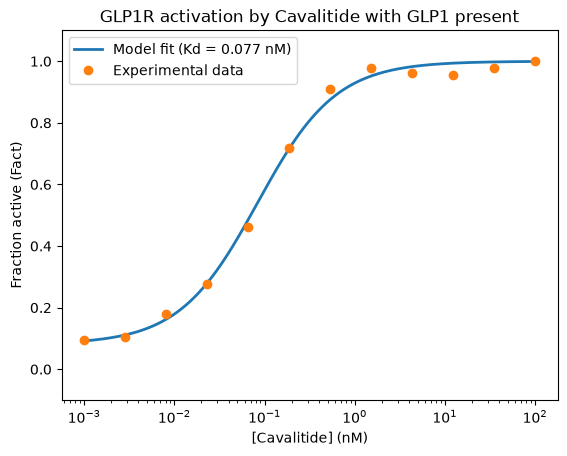

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists"""
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17  # GLP-1
L1 = 0.015  # GLP-1 concentration (fasting)
L2 = np.logspace(-3, 2, 500)

# Load Cavalitide data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Fit Kd2 using curve_fit
popt, pcov = curve_fit(
    lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
    L2_loaded, Fact_loaded,
    p0=[0.1],
    bounds=(0, np.inf)
)

Kd2_fit = popt[0]

# Calculate sum of squared errors
SSE_fit = np.sum(
    (Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2
)

print(f"Fitted Cavalitide Kd = {Kd2_fit:.3f} nM")
print(f"SSE = {SSE_fit:.4f}")

# Plot experimental data and fitted model
plt.figure()

plt.semilogx(
    L2, Fact(L1, L2, Kd1, Kd2_fit),
    lw=2, label=f"Model fit (Kd = {Kd2_fit:.3f} nM)"
)

plt.semilogx(
    L2_loaded, Fact_loaded, "o",
    label="Experimental data"
)

plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present")
plt.legend()
plt.show()


Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

The fitted value of Kd for cavalatide is 0.077nM while the Kd value for semaglutide is 0.35nM. Lower Kd values demonstrate better receptor binding affinity, therefore, Cavalatide has 4.5 times greater binding affinity compared to semaglutide. Advantages of having better receptor binding affinity may contribute to higher potency and more specific binding, essentialy resulting in a more efficient drug. A disadvantage is that low Kd values may come with slow off-rates, potentially causing problems with accumulation that can lead to toxicity. 

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.

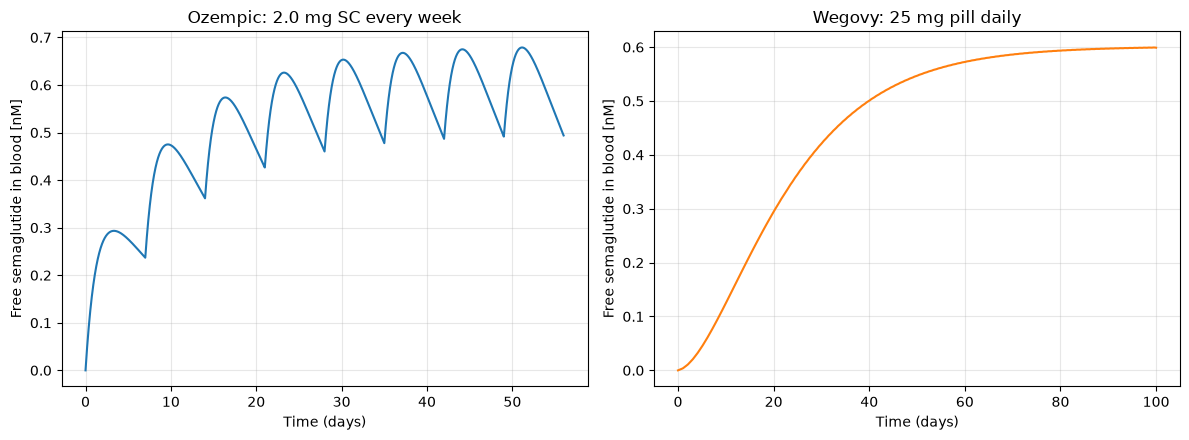

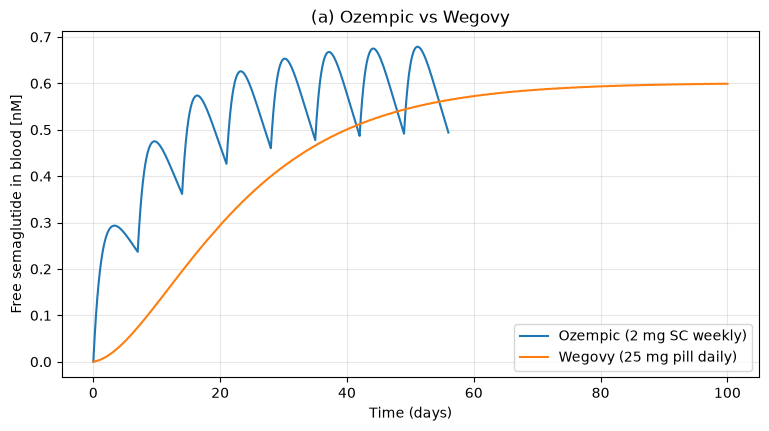

In [6]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams["figure.figsize"] = (9, 4.5)

products = {
    'Ozempic':    dict(Favailable=0.89, ka=0.029,  D=2.0, interval=168, n_doses=8,
                       depot='subcutaneous'),
    'Wegovy':     dict(Favailable=0.01, ka=0.0029, D=25,  interval=24,  n_doses=100,
                       depot='gut (oral)'),
    # Cavalitide: same as Wegovy pill, except faster absorption
    'Cavalitide': dict(Favailable=0.01, ka=0.006,  D=25,  interval=24,  n_doses=100,
                       depot='gut (oral)'),
}

# shared model parameters
ke = 0.0039      # 1/h, elimination rate
V = 10.8         # L
MW = 4113.6      # g/mol
Ffree = 0.01     # fraction free (rest bound to albumin)

def simulate(Favailable, ka, D, interval, n_doses):
    """Repeated dosing every `interval` h using solve_ivp.
    Returns time (h), depot amount (mg), total blood conc (nmol/L)."""

    def ODEfunc(t, y):
        Asc, Cc = y
        dAsc = -ka * Asc                 # depot amount (mg)
        dCc = ka * Asc / V - ke * Cc     # blood concentration (mg/L)
        return [dAsc, dCc]

    t_out, y_out = [], []
    y0 = np.array([0.0, 0.0])
    for i in range(n_doses):
        y0[0] += Favailable * D          # dose enters the depot
        t0 = i * interval
        t_eval = np.linspace(t0, t0 + interval, int(interval * 10) + 1)
        sol = solve_ivp(ODEfunc, (t0, t0 + interval), y0, method='LSODA',
                        t_eval=t_eval, rtol=1e-8, atol=1e-10)
        t_out.append(sol.t)
        y_out.append(sol.y)
        y0 = sol.y[:, -1].copy()

    t = np.concatenate(t_out)
    Asc = np.concatenate([y[0] for y in y_out])
    Cc = np.concatenate([y[1] for y in y_out])
    Cc_nM = Cc * 1e-3 / MW * 1e9         # mg/L -> nmol/L
    return t, Asc, Cc_nM


def run(name, **override):
    p = {**products[name], **override}
    t, Asc, Cc = simulate(p['Favailable'], p['ka'], p['D'], p['interval'], p['n_doses'])
    return t, Asc, Ffree * Cc, p


def last_interval_stats(t, free, p):
    m = t >= t[-1] - p['interval']
    return free[m].mean(), free[m].min(), free[m].max()

t_o, A_o, C_o, p_o = run('Ozempic')
t_w, A_w, C_w, p_w = run('Wegovy')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(t_o / 24, C_o, color='tab:blue')
ax[0].set_title(f"Ozempic: {p_o['D']} mg SC every week")
ax[1].plot(t_w / 24, C_w, color='tab:orange')
ax[1].set_title(f"Wegovy: {p_w['D']} mg pill daily")
for a in ax:
    a.set_xlabel("Time (days)"); a.set_ylabel("Free semaglutide in blood [nM]"); a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.plot(t_o / 24, C_o, label="Ozempic (2 mg SC weekly)")
plt.plot(t_w / 24, C_w, label="Wegovy (25 mg pill daily)")
plt.xlabel("Time (days)"); plt.ylabel("Free semaglutide in blood [nM]")
plt.title("(a) Ozempic vs Wegovy"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.

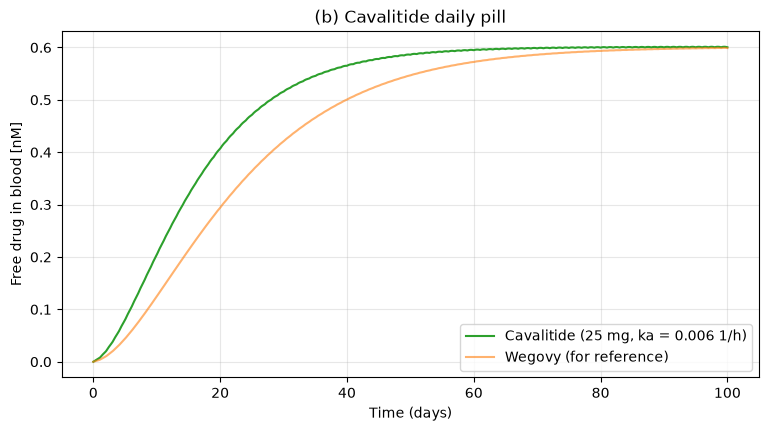

In [7]:
t_c, A_c, C_c, p_c = run('Cavalitide')

plt.plot(t_c / 24, C_c, color='tab:green', label="Cavalitide (25 mg, ka = 0.006 1/h)")
plt.plot(t_w / 24, C_w, color='tab:orange', alpha=0.6, label="Wegovy (for reference)")
plt.xlabel("Time (days)"); plt.ylabel("Free drug in blood [nM]")
plt.title("(b) Cavalitide daily pill"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. 

New dose: 20.8 mg daily


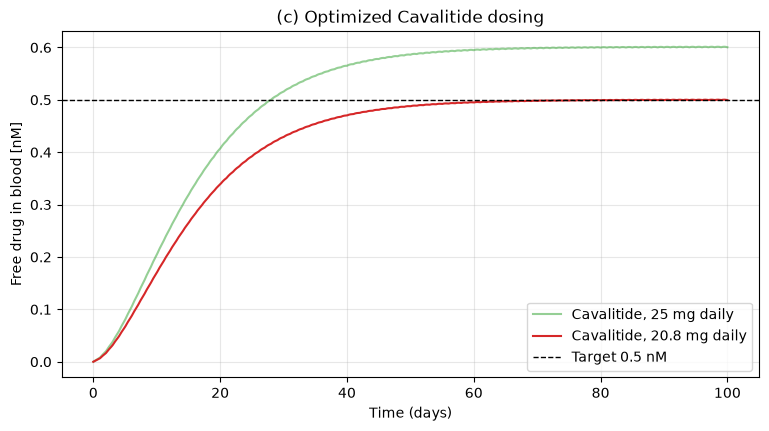

Regimen                          avg   trough    peak  (free nM, last interval)
Ozempic 2 mg weekly            0.608    0.491   0.679
Wegovy 25 mg daily             0.599    0.599   0.599
Cavalitide 25 mg daily         0.601    0.600   0.601
Cavalitide 20.8 mg daily       0.500    0.500   0.500


In [8]:
target = 0.5
avg25 = last_interval_stats(t_c, C_c, p_c)[0]
D_new = round(25 * target / avg25, 1)
print(f"New dose: {D_new} mg daily")

t_n, A_n, C_n, p_n = run('Cavalitide', D=D_new)

plt.plot(t_c / 24, C_c, color='tab:green', alpha=0.5, label="Cavalitide, 25 mg daily")
plt.plot(t_n / 24, C_n, color='tab:red', label=f"Cavalitide, {D_new} mg daily")
plt.axhline(target, color='k', ls='--', lw=1, label="Target 0.5 nM")
plt.xlabel("Time (days)"); plt.ylabel("Free drug in blood [nM]")
plt.title("(c) Optimized Cavalitide dosing"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

print(f"{'Regimen':<28}{'avg':>8}{'trough':>9}{'peak':>8}  (free nM, last interval)")
for label, (t, C, p) in {
    "Ozempic 2 mg weekly":        (t_o, C_o, p_o),
    "Wegovy 25 mg daily":         (t_w, C_w, p_w),
    "Cavalitide 25 mg daily":     (t_c, C_c, p_c),
    f"Cavalitide {D_new} mg daily": (t_n, C_n, p_n),
}.items():
    a, l, h = last_interval_stats(t, C, p)
    print(f"{label:<28}{a:8.3f}{l:9.3f}{h:8.3f}")

What did you change about the dosing strategy and why?

I lowered the Cavalitide dose from 25 mg to about 20.8 mg daily and kept the 24 h interval, which brings the steady-state free drug concentration to about 0.5 nM. In this model the steady-state average depends on dose, bioavailability, clearance, and dosing interval, but not on ka, so the faster absorption mainly changes how quickly each dose enters the blood. Because Cavalitide absorbs faster, a smaller dose reaches the same exposure, making a dose reduction the simplest adjustment for a Phase 1 trial. Stretching the interval to about 29 h with the original 25 mg would also work, but a non-24 h schedule is impractical for patients.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment.

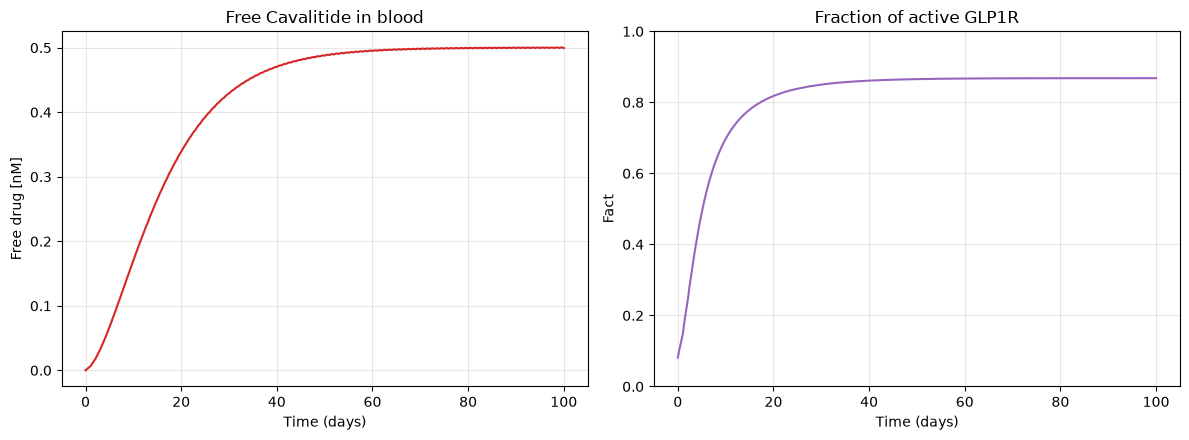

Phase 1 dose (20.8 mg daily): steady-state Fact = 0.868


In [9]:
# ---- PD model from Task 1 ----
def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists"""
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

Kd1 = 0.17                   # nM, GLP-1
L1 = 0.015                   # nM, GLP-1 (fasting)
Kd2 = 0.07696602802733345    # nM, fitted Cavalitide Kd from Task 1

# ---- PK (optimized Phase 1 dose) -> PD ----
D_phase1 = 20.8              # mg daily
t_p1, A_p1, C_p1, p_p1 = run('Cavalitide', D=D_phase1)
F_p1 = Fact(L1, C_p1, Kd1, Kd2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(t_p1 / 24, C_p1, color='tab:red')
ax[0].set_title("Free Cavalitide in blood"); ax[0].set_ylabel("Free drug [nM]")
ax[1].plot(t_p1 / 24, F_p1, color='tab:purple')
ax[1].set_title("Fraction of active GLP1R"); ax[1].set_ylabel("Fact"); ax[1].set_ylim(0, 1)
for a in ax:
    a.set_xlabel("Time (days)"); a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

m = t_p1 >= t_p1[-1] - 24
print(f"Phase 1 dose ({D_phase1} mg daily): steady-state Fact = {F_p1[m].mean():.3f}")

Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


Required free Cavalitide: 0.686 nM
New dose: 28.5 mg daily


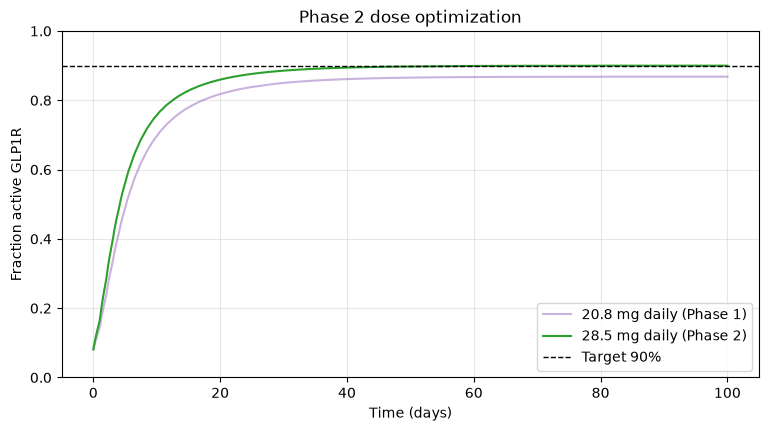

Steady-state Fact at 28.5 mg daily = 0.900


In [10]:
# Free Cavalitide needed for Fact = 0.9 (with GLP-1 present):
#   L2 = Kd2 * (f/(1-f) - L1/Kd1)
f_target = 0.9
L2_target = Kd2 * (f_target / (1 - f_target) - L1 / Kd1)
print(f"Required free Cavalitide: {L2_target:.3f} nM")

# Steady-state average scales linearly with dose, so rescale the Phase 1 dose
avg_p1 = last_interval_stats(t_p1, C_p1, p_p1)[0]
D_new = round(D_phase1 * L2_target / avg_p1, 1)
print(f"New dose: {D_new} mg daily")

t_p2, A_p2, C_p2, p_p2 = run('Cavalitide', D=D_new)
F_p2 = Fact(L1, C_p2, Kd1, Kd2)

plt.plot(t_p1 / 24, F_p1, color='tab:purple', alpha=0.5, label=f"{D_phase1} mg daily (Phase 1)")
plt.plot(t_p2 / 24, F_p2, color='tab:green', label=f"{D_new} mg daily (Phase 2)")
plt.axhline(0.9, color='k', ls='--', lw=1, label="Target 90%")
plt.xlabel("Time (days)"); plt.ylabel("Fraction active GLP1R")
plt.title("Phase 2 dose optimization"); plt.ylim(0, 1); plt.legend(); plt.grid(alpha=0.3)
plt.show()

m = t_p2 >= t_p2[-1] - 24
print(f"Steady-state Fact at {D_new} mg daily = {F_p2[m].mean():.3f}")

I raised the Cavalitide dose from 20.8 mg to about 28.5 mg daily and kept the 24 h interval, because the steady-state concentration depends on dose and dosing interval but not on ka. Phase 1 dosing already gave about 87% active GLP1R at 0.5 nM free drug, so this increase of about 37% in dose raises free drug to about 0.69 nM and receptor activation to about 90%. Because Cavalitide binds tightly (Kd of about 0.077 nM) and the receptors are already near saturation, a 37% higher dose buys only about three more percentage points of activation. The clinical benefit is stronger and more consistent receptor engagement, which should translate to greater efficacy, but with diminishing returns, so the added drug exposure (and potential side effects and cost) should be weighed against that modest gain.

The 90% figure is an equilibrium estimate, so a trial would still need to confirm it in patients.

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

Our simulations suggest Cavalitide is a credible competitor to both semaglutide products. Weekly Ozempic (2 mg) and daily Wegovy (25 mg) both reach an average free concentration of about 0.6 nM. Ozempic oscillates between about 0.49 and 0.68 nM with each injection, while the daily pill gives a nearly flat profile, and Cavalitide as a daily pill behaves the same way. At the Phase 1 target of 0.5 nM, Cavalitide activates about 87% of GLP1R, and a dose of about 28.5 mg daily raises that to about 90% with the same once-daily convenience. Because Cavalitide binds GLP1R tightly (Kd of about 0.077 nM), it reaches high receptor activation at low free concentrations, so even the 25 mg Wegovy dose would give about 89% active receptors. That is a potential efficacy advantage over an oral product with only about 1% bioavailability. It also avoids the injections that make Ozempic less appealing to some patients. However, in this model absorption speed (ka) does not change the steady-state average, so Cavalitide’s advantage would come mainly from its binding affinity rather than its faster absorption.

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

This project relies on several simplifying assumptions. Cavalitide was assumed to share semaglutide’s bioavailability, elimination rate, volume of distribution, and albumin binding, differing only in ka, so the PK predictions are really hypotheses. The model is one-compartment with first-order absorption, and it ignores food effects on oral absorption, variability between patients, and any link between receptor activation and clinical outcomes such as glucose control or weight loss. The PD model assumes instantaneous equilibrium binding and uses a Kd fitted to only 12 in vitro points with GLP-1 fixed at its fasting level. It ignores binding kinetics, receptor internalization, and desensitization. We also lack a semaglutide Kd measured in the same assay, so we cannot directly compare the two drugs’ receptor activation, and the 90% target is a design choice rather than a clinically validated one. In addition, the higher dose needed for 90% activation raises exposure, and potential side effects and cost, which we did not model.

With more time and data, I would estimate Cavalitide’s PK parameters from Phase 1 patient samples and build a population PK/PD model that captures inter-patient variability. I would add binding kinetics (kon/koff) and receptor dynamics to the PD model, and measure semaglutide’s Kd in the same assay for a fair head-to-head comparison. I would also quantify the uncertainty in Kd (for example, by bootstrapping the fit) and run sensitivity analyses on the key parameters. Finally, I would connect receptor activation to clinical endpoints and side-effect risk, and test alternative regimens such as twice-daily or extended-release dosing.

One correction to my earlier explanation: I said Cavalitide’s faster absorption lets a smaller dose reach the same exposure, but in this model that isn’t quite right. The 20.8 mg dose is lower than Wegovy’s 25 mg because the target was 0.5 nM rather than about 0.6 nM, not because of ka. If you reuse that sentence from your Task 2 write-up, I’d change it to say the dose was reduced to hit the lower target concentration, and that ka only affects how quickly each dose is absorbed.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*